# Carbon-aware MARLISA and four-controller comparison

This notebook trains MARLISA with a time-varying carbon reward and compares four controllers:

1. `BasicRBC`;
2. independent SAC with its local electricity reward;
3. MARLISA with CityLearn's district-coupled `MARL` reward; and
4. carbon-aware MARLISA.

All learned controllers use the same dataset, seed, SAC network settings, training schedule, and deterministic final evaluation. Their reward definitions are part of the approaches being compared, so episode reward totals are not comparable across controllers.


## Carbon-aware reward

For building $i$ at time $t$:

$$r_{i,t} = -c_t \max(E_{i,t}, 0)$$

where $c_t$ is grid carbon intensity and $E_{i,t}$ is net electricity consumption. Electricity imported when the grid is carbon intensive therefore receives a larger penalty. Export receives no credit, matching CityLearn's carbon KPI calculation.

Each building receives its own emissions penalty. District emissions are the sum of these local contributions, while the reward scale remains close to the independent SAC baseline. This reward does not include thermal comfort or fairness yet; those are evaluated as outcomes and can be added in the next reward-design stage.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


from src.rewards import CarbonAwareReward
from src.run_carbon_aware_marlisa import run_carbon_aware_marlisa
from src.run_independent_sac import run_independent_sac
from src.run_marlisa import run_marlisa
from src.run_rbc import run_basic_rbc

SCHEMA = PROJECT_ROOT / 'notebooks' / 'data' / 'schema.json'
print(f'Project root: {PROJECT_ROOT}')
print(f'Schema exists: {SCHEMA.is_file()}')


Project root: C:\Users\tanka\Dropbox\08-1 NUS Master in Computing AI specialization\CS5546 AI Planning and Decision Making\02Assignment
Schema exists: True


## Verify the reward calculation

The same 2 kWh import is penalized more when carbon intensity increases. A negative net consumption represents export and receives zero reward under this definition.


In [2]:
reward_example = CarbonAwareReward({'central_agent': False})
example_observations = [
    {'net_electricity_consumption': 2.0, 'carbon_intensity': 0.2},
    {'net_electricity_consumption': 2.0, 'carbon_intensity': 0.6},
    {'net_electricity_consumption': -1.0, 'carbon_intensity': 0.6},
]
pd.DataFrame(example_observations).assign(
    reward=reward_example.calculate(example_observations)
)


,net_electricity_consumption,carbon_intensity,reward
0,2.0,0.2,-0.4
1,2.0,0.6,-1.2
2,-1.0,0.6,-0.0


## Shared experimental configuration

Three episodes provide one exploration episode, one learning episode, and one deterministic evaluation episode. This is a development comparison rather than a convergence study. Use more episodes, held-out data, and multiple seeds for the final report.


In [3]:
SEED = 42
TRAINING_EPISODES = 3
RETRAIN_EXISTING = False
RUN_MISSING_BASELINES = True

SAC_PARAMETERS = {
    'hidden_dimension': (256, 256),
    'discount': 0.99,
    'tau': 0.005,
    'alpha': 0.2,
    'learning_rate': 3e-4,
    'batch_size': 256,
    'replay_buffer_capacity': 100_000,
    'action_scaling_coefficient': 0.5,
    'reward_scaling': 5.0,
    'update_per_time_step': 1,
}

MARLISA_PARAMETERS = {
    'regression_buffer_capacity': 30_000,
    'start_regression_time_step': 2,
    'regression_frequency': 2_500,
    'information_sharing': True,
    'pca_compression': 1.0,
    'iterations': 2,
}

OUTPUTS = {
    'BasicRBC': PROJECT_ROOT / 'outputs' / 'rbc',
    'Independent SAC': PROJECT_ROOT / 'outputs' / 'independent_sac',
    'MARLISA': PROJECT_ROOT / 'outputs' / 'marlisa',
    'Carbon-aware MARLISA': PROJECT_ROOT / 'outputs' / 'carbon_aware_marlisa',
}


## Ensure the three baselines are available

When `RUN_MISSING_BASELINES` is `True`, this cell creates any missing canonical result folder. Existing results are reused unless `RETRAIN_EXISTING` is enabled. SAC and MARLISA training may take several minutes.


In [4]:
def result_exists(controller):
    return (OUTPUTS[controller] / 'kpis.csv').is_file()

if RETRAIN_EXISTING or not result_exists('BasicRBC'):
    run_basic_rbc(
        schema=SCHEMA,
        output_directory=OUTPUTS['BasicRBC'],
        random_seed=SEED,
    )

if RUN_MISSING_BASELINES and (RETRAIN_EXISTING or not result_exists('Independent SAC')):
    print('Training independent SAC...')
    run_independent_sac(
        schema=SCHEMA,
        output_directory=OUTPUTS['Independent SAC'],
        episodes=TRAINING_EPISODES,
        random_seed=SEED,
        reward='independent_sac',
        **SAC_PARAMETERS,
    )

if RUN_MISSING_BASELINES and (RETRAIN_EXISTING or not result_exists('MARLISA')):
    print('Training standard MARLISA...')
    run_marlisa(
        schema=SCHEMA,
        output_directory=OUTPUTS['MARLISA'],
        episodes=TRAINING_EPISODES,
        random_seed=SEED,
        reward='marl',
        **SAC_PARAMETERS,
        **MARLISA_PARAMETERS,
    )

pd.Series({name: result_exists(name) for name in OUTPUTS}, name='results_available')


BasicRBC                True
Independent SAC         True
MARLISA                 True
Carbon-aware MARLISA    True
Name: results_available, dtype: bool

## Train carbon-aware MARLISA

This run uses the same MARLISA architecture and SAC settings as notebook `03`, replacing the district-coupled `MARL` reward with a local carbon-emissions penalty.


In [5]:
if RETRAIN_EXISTING or not result_exists('Carbon-aware MARLISA'):
    carbon_result = run_carbon_aware_marlisa(
        schema=SCHEMA,
        output_directory=OUTPUTS['Carbon-aware MARLISA'],
        episodes=TRAINING_EPISODES,
        random_seed=SEED,
        **SAC_PARAMETERS,
        **MARLISA_PARAMETERS,
    )
else:
    carbon_result = None
    print('Reusing existing carbon-aware MARLISA results.')

print(f"Results saved in: {OUTPUTS['Carbon-aware MARLISA']}")


Reusing existing carbon-aware MARLISA results.
Results saved in: C:\Users\tanka\Dropbox\08-1 NUS Master in Computing AI specialization\CS5546 AI Planning and Decision Making\02Assignment\outputs\carbon_aware_marlisa


## Current saved development results

The following snapshot was generated with seed 42, 720 time steps, and three episodes. The learned controllers had one exploration episode, one learning episode, and one deterministic evaluation episode. Lower values are better.

| District metric | BasicRBC | Independent SAC | MARLISA (`MARL` reward) | Carbon-aware MARLISA |
| --- | ---: | ---: | ---: | ---: |
| Carbon emissions ratio | 1.890 | **0.445** | 0.657 | 0.449 |
| Cost ratio | 1.843 | **0.418** | 0.626 | 0.422 |
| Electricity consumption ratio | 1.900 | **0.452** | 0.667 | 0.456 |
| Daily peak ratio | 1.329 | **0.715** | 0.792 | 0.716 |
| Ramping ratio | 0.924 | 0.889 | **0.870** | 0.887 |

| Comfort metric | BasicRBC | Independent SAC | MARLISA (`MARL` reward) | Carbon-aware MARLISA |
| --- | ---: | ---: | ---: | ---: |
| Average building discomfort | 0.947 | 0.980 | **0.514** | 0.979 |
| Worst-building discomfort | 0.975 | 0.982 | **0.895** | 0.982 |
| Building discomfort gap | 0.066 | **0.004** | 0.656 | 0.006 |

Carbon-aware MARLISA reduced the carbon ratio by 76.2% relative to RBC in this run, but it did not improve on independent SAC after the short training budget. Standard MARLISA's coordinated reward produced a higher carbon ratio than the local electricity and carbon rewards, while lowering average discomfort substantially. Its large discomfort gap shows that the improvement was distributed unevenly across buildings. These results describe one short run and motivate reporting energy, absolute comfort, and the between-building gap together.


## Check whether the runs are comparable

Review this table before interpreting the KPIs. The learned controllers should have the same seed, episode length, episode count, and SAC settings. The intended difference is the controller architecture or reward. RBC does not learn from a reward.


In [6]:
context_rows = []
for controller, directory in OUTPUTS.items():
    metadata_path = directory / 'metadata.json'
    if not metadata_path.is_file():
        continue
    metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    sac = metadata.get('sac_hyperparameters', metadata.get('hyperparameters', {}))
    context_rows.append({
        'controller': controller,
        'seed': metadata.get('random_seed'),
        'time_steps': metadata.get('episode_time_steps', metadata.get('time_steps')),
        'episodes': metadata.get('episodes', 1),
        'reward': metadata.get('reward_choice', 'not used for RBC actions'),
        'batch_size': sac.get('batch_size'),
        'learning_rate': sac.get('learning_rate'),
        'updates_per_step': sac.get('update_per_time_step'),
    })

experiment_context = pd.DataFrame(context_rows).set_index('controller')
display(experiment_context)


,seed,time_steps,episodes,reward,batch_size,learning_rate,updates_per_step
controller,,,,,,,
BasicRBC,42,720,1,not used for RBC actions,NaN,NaN,NaN
Independent SAC,42,720,3,independent_sac,256.0,0.0003,1.0
MARLISA,42,720,3,marl,256.0,0.0003,1.0
Carbon-aware MARLISA,42,720,3,carbon,256.0,0.0003,1.0


## Load all KPI results

CityLearn's primary electricity, carbon, cost, peak, and ramping KPIs are ratios to the corresponding no-control baseline. Lower is better, and 1 represents the baseline. Discomfort proportion is the fraction of occupied periods outside the comfort band.


In [7]:
kpis_by_controller = {}
missing = []
for controller, directory in OUTPUTS.items():
    path = directory / 'kpis.csv'
    if path.is_file():
        kpis_by_controller[controller] = pd.read_csv(path)
    else:
        missing.append(controller)

if missing:
    raise FileNotFoundError(f'Missing results for: {missing}. Run the training cells above.')

print(f'Loaded KPI results for {len(kpis_by_controller)} controllers.')


Loaded KPI results for 4 controllers.


## District-level comparison

This table provides the main energy-system comparison. Carbon-aware MARLISA should primarily be judged by `carbon_emissions_total`, followed by the comfort and fairness checks below.


,BasicRBC,Independent SAC,MARLISA,Carbon-aware MARLISA
cost_function,,,,
carbon_emissions_total,1.890,0.445,0.685,0.449
cost_total,1.843,0.418,0.654,0.422
electricity_consumption_total,1.900,0.452,0.695,0.456
daily_peak_average,1.329,0.715,0.801,0.716
ramping_average,0.924,0.889,0.861,0.887


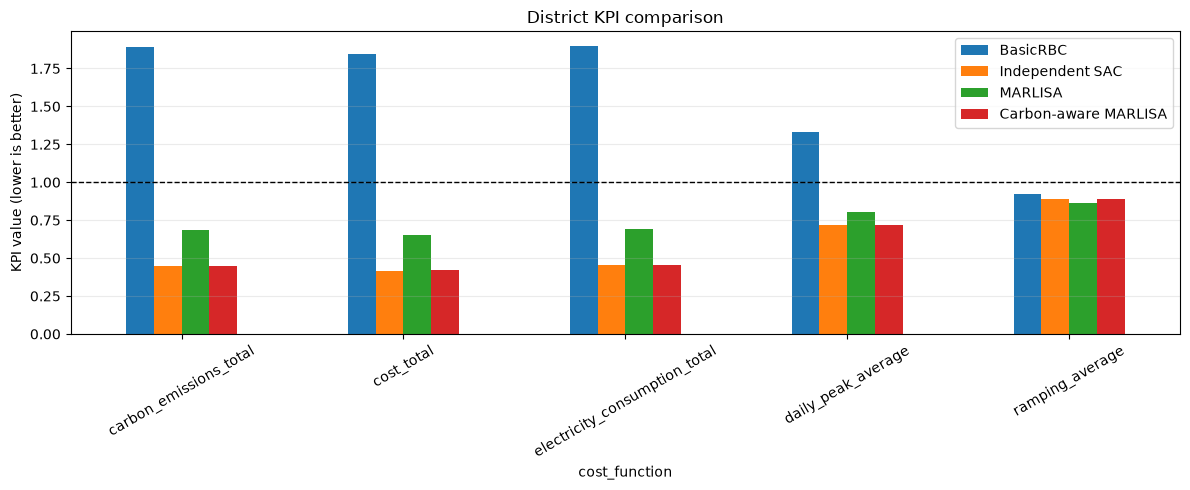

In [8]:
KEY_DISTRICT_KPIS = [
    'carbon_emissions_total',
    'cost_total',
    'electricity_consumption_total',
    'daily_peak_average',
    'ramping_average',
]

district_series = {}
for controller, kpis in kpis_by_controller.items():
    district_series[controller] = (
        kpis.loc[kpis['level'] == 'district']
        .set_index('cost_function')['value']
    )
district_comparison = pd.concat(district_series, axis=1)
district_comparison = district_comparison.loc[
    [kpi for kpi in KEY_DISTRICT_KPIS if kpi in district_comparison.index]
]
display(district_comparison.round(3))

ax = district_comparison.plot.bar(figsize=(12, 5))
ax.axhline(1.0, color='black', linestyle='--', linewidth=1, label='No-control reference')
ax.set_ylabel('KPI value (lower is better)')
ax.set_title('District KPI comparison')
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


## Improvement relative to RBC

Positive percentages indicate a lower KPI than RBC. This is a descriptive single-run comparison.


In [9]:
rbc = district_comparison['BasicRBC']
improvement_vs_rbc = district_comparison.drop(columns='BasicRBC').apply(
    lambda values: 100.0 * (rbc - values) / rbc
)
display(improvement_vs_rbc.round(1).style.format('{:.1f}%'))


,Independent SAC,MARLISA,Carbon-aware MARLISA
cost_function,,,
carbon_emissions_total,76.4%,63.8%,76.2%
cost_total,77.3%,64.5%,77.1%
electricity_consumption_total,76.2%,63.4%,76.0%
daily_peak_average,46.2%,39.7%,46.1%
ramping_average,3.8%,6.9%,4.0%


## Building-level carbon comparison

District totals can hide uneven building behavior. This table shows each building's carbon-emissions ratio to its no-control reference.


,BasicRBC,Independent SAC,MARLISA,Carbon-aware MARLISA
name,,,,
Building_1,1.998,0.409,0.503,0.407
Building_2,1.936,0.406,0.809,0.421
Building_3,1.735,0.522,0.742,0.519


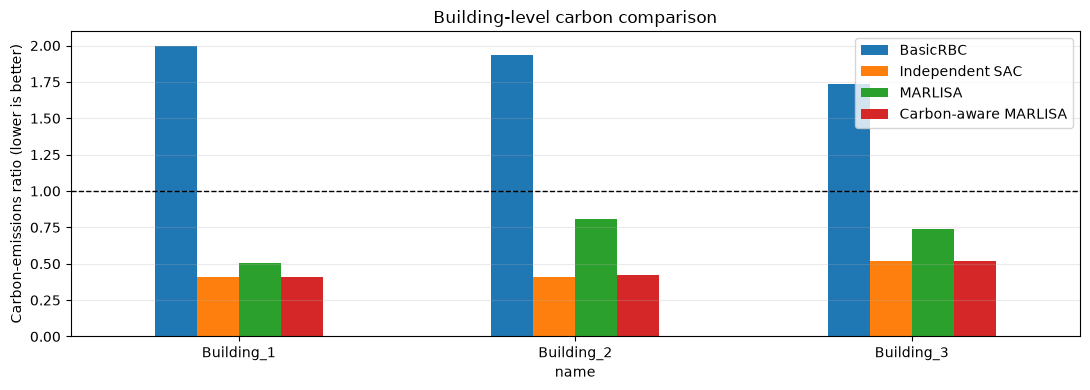

In [10]:
building_carbon = {}
for controller, kpis in kpis_by_controller.items():
    building_carbon[controller] = (
        kpis.loc[
            (kpis['level'] == 'building')
            & (kpis['cost_function'] == 'carbon_emissions_total')
        ]
        .set_index('name')['value']
    )
building_carbon = pd.concat(building_carbon, axis=1)
display(building_carbon.round(3))

ax = building_carbon.plot.bar(figsize=(11, 4))
ax.axhline(1.0, color='black', linestyle='--', linewidth=1)
ax.set_ylabel('Carbon-emissions ratio (lower is better)')
ax.set_title('Building-level carbon comparison')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


## Comfort and fairness comparison

Carbon reduction should not be evaluated alone. The table reports average discomfort, worst-building discomfort, the best building, and the gap between worst and best. Lower values are better.


In [11]:
fairness_rows = []
for controller, kpis in kpis_by_controller.items():
    discomfort = kpis.loc[
        (kpis['level'] == 'building')
        & (kpis['cost_function'] == 'discomfort_proportion'),
        ['name', 'value'],
    ].dropna()
    worst = discomfort.loc[discomfort['value'].idxmax()]
    best = discomfort.loc[discomfort['value'].idxmin()]
    fairness_rows.append({
        'controller': controller,
        'average_discomfort': discomfort['value'].mean(),
        'worst_discomfort': worst['value'],
        'best_discomfort': best['value'],
        'discomfort_gap': worst['value'] - best['value'],
        'worst_building': worst['name'],
    })
fairness_comparison = pd.DataFrame(fairness_rows).set_index('controller')
display(fairness_comparison.round(3))


,average_discomfort,worst_discomfort,best_discomfort,discomfort_gap,worst_building
controller,,,,,
BasicRBC,0.947,0.975,0.908,0.066,Building_1
Independent SAC,0.980,0.982,0.978,0.004,Building_1
MARLISA,0.511,0.846,0.307,0.539,Building_1
Carbon-aware MARLISA,0.979,0.982,0.976,0.006,Building_1


## Carbon-comfort trade-off

A controller closer to the lower-left corner has both lower district carbon and lower worst-building discomfort. This plot makes any comfort cost of carbon optimization visible.


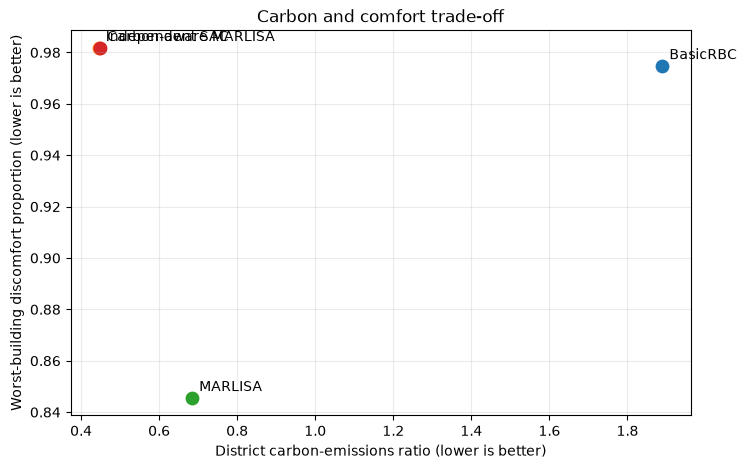

,district_carbon,worst_discomfort,discomfort_gap
BasicRBC,1.890,0.975,0.066
Independent SAC,0.445,0.982,0.004
MARLISA,0.685,0.846,0.539
Carbon-aware MARLISA,0.449,0.982,0.006


In [12]:
tradeoff = pd.DataFrame({
    'district_carbon': district_comparison.loc['carbon_emissions_total'],
    'worst_discomfort': fairness_comparison['worst_discomfort'],
    'discomfort_gap': fairness_comparison['discomfort_gap'],
}).dropna()

fig, ax = plt.subplots(figsize=(8, 5))
for controller, row in tradeoff.iterrows():
    ax.scatter(row['district_carbon'], row['worst_discomfort'], s=80)
    ax.annotate(controller, (row['district_carbon'], row['worst_discomfort']), xytext=(5, 5), textcoords='offset points')
ax.set_xlabel('District carbon-emissions ratio (lower is better)')
ax.set_ylabel('Worst-building discomfort proportion (lower is better)')
ax.set_title('Carbon and comfort trade-off')
ax.grid(alpha=0.25)
plt.show()

display(tradeoff.round(3))


## Automatic single-run summary

This cell identifies the best controller for each displayed metric. Treat it as a convenient description of this seed, not a statistical conclusion.


In [13]:
summary_rows = []
for metric in district_comparison.index:
    values = district_comparison.loc[metric].dropna()
    summary_rows.append({
        'metric': metric,
        'best_controller': values.idxmin(),
        'best_value': values.min(),
    })
for metric in ['average_discomfort', 'worst_discomfort', 'discomfort_gap']:
    values = fairness_comparison[metric].dropna()
    summary_rows.append({
        'metric': metric,
        'best_controller': values.idxmin(),
        'best_value': values.min(),
    })
summary = pd.DataFrame(summary_rows).set_index('metric')
display(summary.round(3))


,best_controller,best_value
metric,,
carbon_emissions_total,Independent SAC,0.445
cost_total,Independent SAC,0.418
electricity_consumption_total,Independent SAC,0.452
daily_peak_average,Independent SAC,0.715
ramping_average,MARLISA,0.861
average_discomfort,MARLISA,0.511
worst_discomfort,MARLISA,0.846
discomfort_gap,Independent SAC,0.004


## Interpretation limits and next step

The current comparison uses one short training run and evaluates on the same simulation period used during training. It can verify the implementation and expose obvious trade-offs, but it cannot establish that one algorithm is generally better.

For the report, define held-out evaluation periods, use longer equal training budgets, repeat all learned controllers over the same seeds, and report means with variation. The next reward extension can add explicit comfort and worst-building fairness penalties to the carbon term while preserving this evaluation table.
